# Quantum Adders Comparison - Performance and Noise Resilience

Version 2. Changes from the original notebook:

1. **No more crash at n ≥ 6.** Large circuits are simulated with Aer's matrix-product-state (MPS) method instead of the statevector method (see the note below).
2. **One function for every n.** The six copy-pasted cells (n = 3…8) are replaced by `run_experiment(n)` and a loop. Results go to a `pandas` table and `success_rates.csv`.
3. **Circuit metrics.** Gate count, depth, `count_ops`, two-qubit gates, T-count, T-depth, and depth / two-qubit count after routing to the FakeKyiv and FakeAachen devices. Saved to `circuit_metrics.csv`.
4. **Two fixes.** The AQFT adder now measures its carry-out qubit, and the `basis_gates` experiment no longer runs with noiseless gates.

## Note: why the simulation crashes at n = 6

**Short version:** the QCLA circuit at n = 6 has 27 qubits. A statevector of 27 qubits takes 2 GiB, and a noisy simulation needs several of them at once. The machine runs out of RAM, the operating system kills the Python process, and Jupyter reports *"The Kernel crashed"*.

### Memory grows as 2^qubits

Aer's default method stores the full statevector: 2^q complex amplitudes × 16 bytes each. Every extra qubit doubles the memory. Qubits per adder:

| n | RCA (3n+1) | AQFT (2n+1) | QCLA (4n+1+ancillas) | QCLA statevector |
|---|---|---|---|---|
| 3 | 10 | 7 | 13 | 128 KiB |
| 4 | 13 | 9 | 18 | 4 MiB |
| 5 | 16 | 11 | 22 | 64 MiB |
| **6** | 19 | 13 | **27** | **2 GiB** |
| 7 | 22 | 15 | 31 | 32 GiB |
| 8 | 25 | 17 | 37 | 2 TiB |

RCA and AQFT stay small. The QCLA computes the sum *out of place* (a separate sum register `s`, carry register `c` and propagate ancillas), so it uses the most qubits. That is the circuit that kills the kernel.

### Why the ideal run at n = 6 survived but the noisy run did not

* **Ideal:** all measurements are at the end, so Aer simulates the circuit **once** and samples all 4096 shots from that single final state. One 2 GiB vector fits in memory.
* **Noisy:** every shot draws its own random errors, so Aer must simulate each shot as a separate trajectory. It can run shots in parallel, and each parallel trajectory needs its own working copy of the 2 GiB state. Together with the rest of the Python process, this most likely pushed memory past what your PC had free.

The allocation fails inside Aer's C++ code, so Python never gets a `MemoryError` it could catch: the process is simply killed. The printed output stops after "RCA" probably because the remaining lines were still buffered when the process died.

n = 7 (32 GiB) and n = 8 (2 TiB) would fail even without noise. No PC can run them with the statevector method.

### The method used here: matrix product states (MPS)

`AerSimulator(method="matrix_product_state")` stores the state as a chain of small tensors, one per qubit. Its memory grows with how **entangled** the state is, not with 2^q. These adders are a good fit:

* The inputs are classical bit strings, and RCA and QCLA are reversible classical circuits. In the ideal case the state stays a product state; the Toffoli decompositions only create short-lived entanglement.
* AQFT does create entanglement, but only inside the (n+1)-qubit QFT register.

MPS is exact here (Aer only truncates singular values below ~1e-16), so the success rates are statistically the same as with the statevector method. Measured on a 7 GB, 2-core machine: n = 8 with 37 qubits runs in seconds under depolarizing noise and in under a minute per adder under the FakeKyiv noise model with 1024 shots.

MPS is also much **faster** for these noisy runs. Measured here under the FakeKyiv noise model, 256 shots:

| Circuit | Qubits | MPS | Statevector |
|---|---|---|---|
| QCLA n=3 | 13 | 2.3 s | 4.0 s |
| RCA n=4 | 13 | 2.7 s | 7.3 s |
| QCLA n=5 | 22 | 3.4 s | not finished after 10 min |

So the notebook uses statevector only for ideal runs up to 24 qubits (one simulation, ≤ 256 MiB) and MPS for everything else.

### Going further

* **Larger n with MPS.** The last experiment section runs n = 10 and n = 12 (QCLA: 46 and 56 qubits). Runtime grows with shots × gates, because every noisy shot is its own trajectory. Lower `shots` if it gets slow.
* **Real hardware.** Above roughly 50-60 qubits, or for circuits that create heavy entanglement (for example a full QFT on many qubits), simulation stops being practical. FakeKyiv has 127 qubits and FakeAachen 156, so the real devices fit every adder in this study. A ready-to-use `SamplerV2` cell is at the end (off by default because it spends IBM Quantum time).
* **Fewer qubits.** An in-place carry-lookahead variant (writing the sum back into `b`) would drop the `s` register and save n+1 qubits.

### Caveat on the hardware noise environments

The circuits are transpiled against the simulator, not against the device, so there are no SWAPs for limited connectivity. The FakeKyiv / FakeAachen success rates are therefore optimistic. The metrics section shows the extra depth and two-qubit gates that routing on the real coupling maps would add.

In [2]:
import time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Gate
from qiskit.circuit.library import CXGate, CCXGate, TGate, TdgGate, SGate, SdgGate, ZGate
from qiskit_aer import AerSimulator

## Adder definitions (unchanged)

In [3]:
class Carry(Gate):
    def __init__(self):
        super().__init__(name="Carry", num_qubits=4, params=[])
        qc = QuantumCircuit(4, name=self.name)
        c_in, a, b, c_out = 0, 1, 2, 3
        qc.append(CCXGate(), [a, b, c_out])
        qc.append(CXGate(),  [a, b])
        qc.append(CCXGate(), [c_in, b, c_out])
        self.definition = qc

class Sum(Gate):
    def __init__(self):
        super().__init__(name="Sum", num_qubits=3, params=[])
        qc = QuantumCircuit(3, name=self.name)
        c_in, a, b = 0, 1, 2
        qc.cx(a, b)
        qc.cx(c_in, b)
        self.definition = qc

class RippleCarryAdder(Gate):
    def __init__(self, n: int):
        num_q = 3 * n + 1
        super().__init__(name="RCA", num_qubits=num_q, params=[])
        
        carry    = Carry()
        sum_gate = Sum()
        i_carry  = carry.inverse()
        
        qc = QuantumCircuit(num_q, name=self.name)

        for i in range(0, num_q - 3, 3):
            qc.append(carry, [i, i + 1, i + 2, i + 3])

        qc.cx(num_q - 3, num_q - 2)
        qc.append(sum_gate, [num_q - 4, num_q - 3, num_q - 2])

        for j in range(num_q - 4, 0, -3):
            qc.append(i_carry,  [j - 3, j - 2, j - 1, j])
            qc.append(sum_gate, [j - 3, j - 2, j - 1])

        self.definition = qc

class QFT(Gate):
    def __init__(self, n: int, do_swaps: bool = True):
        self.do_swaps = do_swaps
        super().__init__(name="QFT", num_qubits=n, params=[])
        
        qc = QuantumCircuit(n, name=self.name)
        for j in range(n - 1, -1, -1):
            qc.h(j)
            for k in range(j - 1, -1, -1):
                lam = np.pi / (2.0 ** (j - k))
                qc.cp(lam, k, j)

        if self.do_swaps:
            for i in range(n // 2):
                qc.swap(i, n - i - 1)

        self.definition = qc

class AQFT(Gate):
    def __init__(self, n: int, do_swap: bool = True):
        self.do_swap = do_swap
        super().__init__(name="AQFT", num_qubits=n, params=[])
        
        qc = QuantumCircuit(n, name=self.name)
        m = int(np.ceil(np.log2(n))) 

        for j in range(n - 1, -1, -1):
            qc.h(j)
            for k in range(j - 1, max(j - m, -1), -1):
                lam = np.pi / (2.0 ** (j - k))
                qc.cp(lam, k, j)
                
        if self.do_swap:
            for i in range(n // 2):
                qc.swap(i, n - i - 1)

        self.definition = qc

class QFTDraperAdder(Gate):
    def __init__(self, n: int):
        num_q = 2 * n + 1
        super().__init__(name="QFTDraper", num_qubits=num_q, params=[])
        qc = QuantumCircuit(num_q, name=self.name)
        qr_a = list(range(n))
        qr_b = list(range(n, 2 * n + 1))
        
        qc.append(QFT(n + 1, do_swaps=False), qr_b)
        
        for j in range(n):
            for k in range(n - j + 1):
                lam = np.pi / (2 ** k)
                qc.cp(lam, qr_a[j], qr_b[j + k])
                
        qc.append(QFT(n + 1, do_swaps=False).inverse(), qr_b)
        self.definition = qc

class AQFTDraperAdder(Gate):
    def __init__(self, n: int):
        num_q = 2 * n + 1
        super().__init__(name="AQFTDraper", num_qubits=num_q, params=[])
        
        qc = QuantumCircuit(num_q, name=self.name)
        reg_a = list(range(n))
        reg_b = list(range(n, 2 * n + 1))
        
        qc.append(AQFT(n + 1, do_swap=False), reg_b)
        
        m = int(np.ceil(np.log2(n + 1))) if n > 0 else 0
        for k in range(m + 1):
            lam = np.pi / (2 ** k)
            for j in range(min(n, n - k + 1)):
                qc.cp(lam, reg_a[j], reg_b[j + k])
                
        qc.append(AQFT(n + 1, do_swap=False).inverse(), reg_b)
        
        self.definition = qc

# ---------------------------------------------------------
# Quantum Carry-Lookahead Adder (QCLA)
# Developed by Claude
# ---------------------------------------------------------
def _ptree(n):
    idx, k = {}, 0
    logn = int(np.floor(np.log2(n))) if n >= 1 else 0
    for t in range(1, logn + 1):
        for m in range(1, n // (2 ** t)):
            idx[(t, m)] = k; k += 1
    return idx, k, logn

def _carry_ccx(n, cmap, pmap, ancmap):
    Pidx, _, logn = _ptree(n)
    P = lambda t, m: pmap[m] if t == 0 else ancmap[(t, m)]
    g = []
    
    for t in range(1, logn + 1):
        for m in range(1, n // (2 ** t)):
            g.append((P(t - 1, 2 * m), P(t - 1, 2 * m + 1), P(t, m)))
            
    for t in range(1, logn + 1):
        for m in range(0, n // (2 ** t)):
            g.append((P(t - 1, 2 * m + 1),
                      cmap[2 ** t * m + 2 ** (t - 1) - 1],
                      cmap[2 ** t * m + 2 ** t - 1]))
                      
    if n >= 2:
        for t in range(int(np.floor(np.log2((2 * n) / 3.0))), 0, -1):
            for m in range(1, (n - 2 ** (t - 1)) // (2 ** t) + 1):
                g.append((P(t - 1, 2 * m),
                          cmap[2 ** t * m - 1],
                          cmap[2 ** t * m + 2 ** (t - 1) - 1]))
                          
    for t in range(logn, 0, -1):
        for m in range(1, n // (2 ** t)):
            g.append((P(t - 1, 2 * m), P(t - 1, 2 * m + 1), P(t, m)))
            
    return g

class CarryLookaheadAdder(Gate):
    def __init__(self, n: int):
        Pidx, pk, logn = _ptree(n)
        num_q = 4 * n + 1 + pk
        super().__init__(name="QCLA", num_qubits=num_q, params=[])
        
        qc = QuantumCircuit(num_q, name=self.name)
        
        a = list(range(n))
        b = list(range(n, 2 * n))
        s = list(range(2 * n, 3 * n + 1))
        c = list(range(3 * n + 1, 4 * n + 1))
        panc = list(range(4 * n + 1, 4 * n + 1 + pk))
        
        cmap = c
        pmap = b
        ancmap = {k: panc[v] for k, v in Pidx.items()} if pk > 0 else {}
        cg = _carry_ccx(n, cmap, pmap, ancmap)

        for i in range(n): qc.ccx(a[i], b[i], c[i])         
        for i in range(n): qc.cx(a[i], b[i])                
        for x1, x2, tg in cg: qc.ccx(x1, x2, tg)            
        for i in range(n):                                  
            qc.cx(b[i], s[i])
            if i >= 1: qc.cx(c[i - 1], s[i])
        qc.cx(c[n - 1], s[n])                               
        for x1, x2, tg in reversed(cg): qc.ccx(x1, x2, tg)  
        for i in range(n): qc.cx(a[i], b[i])                
        for i in range(n): qc.ccx(a[i], b[i], c[i])         

        self.definition = qc

## Noise models

`gate_level_noise_model` is new. It is used only by the `basis_gates` experiment, where Toffolis stay as native `ccx` gates and therefore need their own error (see that section).

In [4]:
from qiskit_aer.noise import NoiseModel, depolarizing_error
from qiskit_ibm_runtime.fake_provider import FakeKyiv, FakeAachen

# 1. Noise models from fake hardware backends (calibration snapshots shipped with qiskit-ibm-runtime)
fake_backend = FakeKyiv()
fake_backend2 = FakeAachen()
hardware_noise_model1 = NoiseModel.from_backend(fake_backend)
hardware_noise_model2 = NoiseModel.from_backend(fake_backend2)

# 2. Custom depolarizing model on two-qubit gates
custom_noise_model_1 = NoiseModel()
custom_noise_model_1.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ['cx', 'cp'])

# 3. Same, plus a 3-qubit depolarizing error on native Toffolis
gate_level_noise_model = NoiseModel()
gate_level_noise_model.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ['cx', 'cp'])
gate_level_noise_model.add_all_qubit_quantum_error(depolarizing_error(0.01, 3), ['ccx'])

noise_environments = {
    "Ideal": None,
    "Depolarizing (p=0.01)": custom_noise_model_1,
    "Hardware (FakeKyiv)": hardware_noise_model1,
    "Hardware (FakeAachen)": hardware_noise_model2,
}
env_names = list(noise_environments.keys())

## Evaluation circuit

One fix, in the measurement only. The `AQFTDraperAdder` already computes the carry-out: `reg_b` has n + 1 qubits and the carry lands on qubit `2n`. But the AQFT/QFT branch here measured `range(n)`, i.e. qubits `n … 2n-1`, so qubit `2n` was never read and the top classical bit was always 0. For 3 + 2 = 5 the expected carry is 0, so the old code happened to give the right target, but it counted outcomes with a wrong carry as successes. It now measures all n + 1 sum bits, like the other adders. The adder class is unchanged.

In [5]:
def setup_evaluation_circuit(adder_gate, n, x, y):
    total_qubits = adder_gate.num_qubits
    qc = QuantumCircuit(total_qubits, n + 1)

    if adder_gate.name == "RCA":
        # Interleaved RCA encoding: a_i = 3*i + 1, b_i = 3*i + 2
        for i in range(n):
            if (x >> i) & 1: qc.x(3 * i + 1)
            if (y >> i) & 1: qc.x(3 * i + 2)
    else:
        # Contiguous blocks for AQFT and QCLA
        for i in range(n):
            if (x >> i) & 1: qc.x(i)
            if (y >> i) & 1: qc.x(n + i)

    qc.append(adder_gate, range(total_qubits))

    if adder_gate.name == "RCA":
        # Sum bits replace register b (3*i + 2); carry-out is qubit 3n
        for i in range(n): qc.measure(3 * i + 2, i)
        qc.measure(3 * n, n)
    elif adder_gate.name in ["AQFTDraper", "QFTDraper"]:
        # n sum bits plus the carry-out at qubit 2n   (was range(n): carry-out never measured)
        for i in range(n + 1): qc.measure(n + i, i)
    elif adder_gate.name == "QCLA":
        for i in range(n + 1): qc.measure(2 * n + i, i)

    return qc

## Simulation helpers

`pick_method` uses statevector only for ideal runs up to `STATEVECTOR_MAX_QUBITS` and MPS for every noisy run (faster, and memory no longer grows as 2^q). Each result row records which method ran and how long it took.

In [6]:
STATEVECTOR_MAX_QUBITS = 24          # 2^24 * 16 B = 256 MiB per statevector

ADDER_COLORS = {"RCA": "#2a78d6", "AQFT": "#eb6834", "QCLA": "#1baf7a"}
ADDER_MARKERS = {"RCA": "o", "AQFT": "s", "QCLA": "^"}


def make_adders(n):
    return {"RCA": RippleCarryAdder(n), "AQFT": AQFTDraperAdder(n), "QCLA": CarryLookaheadAdder(n)}


def pick_method(num_qubits, noisy):
    if not noisy and num_qubits <= STATEVECTOR_MAX_QUBITS:
        return "statevector"
    return "matrix_product_state"


def run_experiment(n, x=3, y=2, shots=4096, environments=None, basis_gates=None,
                   seed=1234, verbose=True):
    """Run every adder in every noise environment. Returns a list of result rows."""
    environments = environments or noise_environments
    target = bin(x + y)[2:].zfill(n + 1)
    rows = []
    for env_name, noise in environments.items():
        if verbose: print(f"\nn={n} | {env_name}")
        for adder_name, gate in make_adders(n).items():
            method = pick_method(gate.num_qubits, noise is not None)
            sim = AerSimulator(method=method, noise_model=noise, seed_simulator=seed)
            qc = setup_evaluation_circuit(gate, n, x, y)
            if basis_gates is None:
                qc_t = transpile(qc, sim, optimization_level=1, seed_transpiler=seed)
            else:
                qc_t = transpile(qc, basis_gates=basis_gates, optimization_level=1, seed_transpiler=seed)
            t0 = time.perf_counter()
            counts = sim.run(qc_t, shots=shots).result().get_counts()
            elapsed = time.perf_counter() - t0
            rate = counts.get(target, 0) / shots
            rows.append(dict(n=n, environment=env_name, adder=adder_name, qubits=gate.num_qubits,
                             method=method, shots=shots, success_rate=rate,
                             sim_depth=qc_t.depth(), sim_ops=dict(qc_t.count_ops()),
                             runtime_s=round(elapsed, 2)))
            if verbose:
                print(f"  {adder_name:5s} {gate.num_qubits:3d} qubits  {method:21s} "
                      f"{rate*100:5.1f}% success  ({elapsed:.1f} s)")
    return rows


def plot_success_bars(df_n, title):
    """Grouped bar chart in the style of the original notebook."""
    envs = list(dict.fromkeys(df_n["environment"]))
    xi = np.arange(len(envs)); width = 0.25
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for i, adder in enumerate(ADDER_COLORS):
        rates = [df_n[(df_n.environment == e) & (df_n.adder == adder)].success_rate.iloc[0] for e in envs]
        ax.bar(xi + (i - 1) * width, rates, width, label=adder, color=ADDER_COLORS[adder],
               edgecolor="white", linewidth=2)
    ax.set_ylabel("Success probability")
    ax.set_title(title)
    ax.set_xticks(xi); ax.set_xticklabels(envs)
    ax.axhline(1.0, color="black", linestyle="--", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False, ncol=3, loc="upper center")
    ax.set_ylim(0, 1.22)
    ax.set_yticks(np.arange(0, 1.01, 0.2))
    plt.show()

## Functional verification: many sums, exact probabilities

Before looking at noise, this checks that each adder actually adds. For every input pair (x, y) with n-bit inputs it computes the **exact** probability of reading the correct (n+1)-bit sum, with no shot noise (Aer's `save_probabilities_dict`). `QFTDraper`, the full-QFT adder already defined above, is included as a reference: it should be exact, so any AQFT error must come from the approximation and not from wiring or bit order.

Results on all 2^(2n) input pairs:

* **RCA, QCLA and QFTDraper are exact** for every input: probability 1 of the correct sum.
* **AQFTDraper is not**, and its errors sit almost entirely on the **most significant bits, the carry most of all**. The low bits are always correct for these sizes. Truncating the small rotations removes the fine phase information that the high bits depend on. That is why leaving the carry unmeasured made AQFT look more accurate: it skipped the least accurate bit.

In [7]:
def encode_inputs(qc, adder_name, n, x, y):
    for i in range(n):
        if (x >> i) & 1: qc.x(3 * i + 1 if adder_name == "RCA" else i)
        if (y >> i) & 1: qc.x(3 * i + 2 if adder_name == "RCA" else n + i)


def output_qubits(adder_name, n):
    """Sum qubits, least significant first, carry-out last."""
    if adder_name == "RCA":
        return [3 * i + 2 for i in range(n)] + [3 * n]
    if adder_name in ("AQFTDraper", "QFTDraper"):
        return list(range(n, 2 * n + 1))
    return list(range(2 * n, 3 * n + 1))                # QCLA


def verify_adder(gate, n, pairs=None):
    """Exact P(correct sum) and per-bit error probability for each input pair."""
    pairs = pairs or [(a, b) for a in range(2 ** n) for b in range(2 ** n)]
    outs = output_qubits(gate.name, n)
    circs = []
    for a, b in pairs:
        qc = QuantumCircuit(gate.num_qubits)
        encode_inputs(qc, gate.name, n, a, b)
        qc.append(gate, range(gate.num_qubits))
        qc.save_probabilities_dict(outs)
        circs.append(qc)
    sim = AerSimulator(method="matrix_product_state")
    result = sim.run(transpile(circs, sim)).result()
    rows = []
    for idx, (a, b) in enumerate(pairs):
        probs = result.data(idx)["probabilities"]      # key bit i = outs[i]
        target = a + b
        bit_err = [sum(p for k, p in probs.items() if ((k ^ target) >> i) & 1) for i in range(n + 1)]
        rows.append(dict(adder=gate.name, n=n, x=a, y=b, sum=target,
                         p_correct=probs.get(target, 0.0), **{f"err_bit{i}": e for i, e in enumerate(bit_err)}))
    return pd.DataFrame(rows)


VERIFY_N = [2, 3, 4, 5]
ver = pd.concat([verify_adder(G(n), n)
                 for n in VERIFY_N
                 for G in (RippleCarryAdder, QFTDraperAdder, AQFTDraperAdder, CarryLookaheadAdder)],
                ignore_index=True)

def _summary(g):
    worst = g.loc[g.p_correct.idxmin()]
    return pd.Series({"input pairs": len(g),
                      "mean P(correct)": round(g.p_correct.mean(), 4),
                      "min P(correct)": round(g.p_correct.min(), 4),
                      "pairs with P < 0.999": int((g.p_correct < 0.999).sum()),
                      "worst case": f"{int(worst.x)} + {int(worst.y)} = {int(worst['sum'])}"})

display(ver.groupby(["n", "adder"], sort=False).apply(_summary))

input pairs  mean P(correct)  min P(correct)  \
n adder                                                      
2 RCA                  16           1.0000          1.0000   
  QFTDraper            16           1.0000          1.0000   
  AQFTDraper           16           0.9268          0.8536   
  QCLA                 16           1.0000          1.0000   
3 RCA                  64           1.0000          1.0000   
  QFTDraper            64           1.0000          1.0000   
  AQFTDraper           64           0.8322          0.4268   
  QCLA                 64           1.0000          1.0000   
4 RCA                 256           1.0000          1.0000   
  QFTDraper           256           1.0000          1.0000   
  AQFTDraper          256           0.9535          0.8211   
  QCLA                256           1.0000          1.0000   
5 RCA                1024           1.0000          1.0000   
  QFTDraper          1024           1.0000          1.0000   
  AQFTDraper         1024           0.9227          0.7008   
  QCLA               1024           1.0000          1.0000   

              pairs with P < 0.999    worst case  
n adder                                           
2 RCA                            0     0 + 0 = 0  
  QFTDraper                      0     3 + 1 = 4  
  AQFTDraper                     8     3 + 0 = 3  
  QCLA                           0     0 + 0 = 0  
3 RCA                            0     0 + 0 = 0  
  QFTDraper                      0     2 + 3 = 5  
  AQFTDraper                    48     5 + 3 = 8  
  QCLA                           0     0 + 0 = 0  
4 RCA                            0     0 + 0 = 0  
  QFTDraper                      0     2 + 5 = 7  
  AQFTDraper                   192    9 + 7 = 16  
  QCLA                           0     0 + 0 = 0  
5 RCA                            0     0 + 0 = 0  
  QFTDraper                      0  28 + 26 = 54  
  AQFTDraper                   896  25 + 15 = 40  
  QCLA                           0     0 + 0 = 0

### Where the AQFT errors land

Average probability that each output bit is wrong, over all input pairs. Bit 0 is the least significant bit; the last bit is the carry-out.

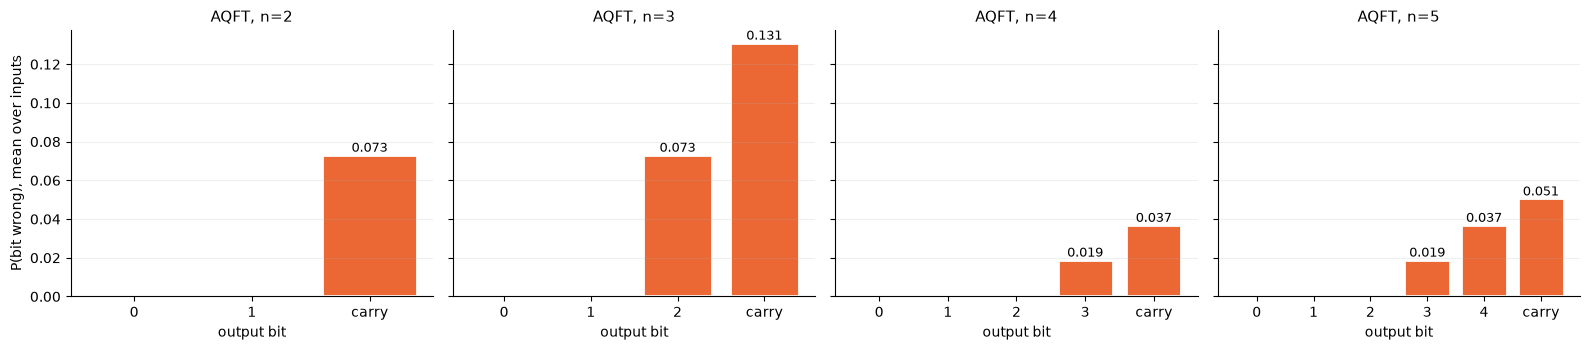

In [8]:
aq = ver[ver.adder == "AQFTDraper"]
fig, axes = plt.subplots(1, len(VERIFY_N), figsize=(16, 3.6), sharey=True)
for ax, n in zip(axes, VERIFY_N):
    d = aq[aq.n == n]
    errs = [d[f"err_bit{i}"].mean() for i in range(n + 1)]
    labels = [str(i) for i in range(n)] + ["carry"]
    ax.bar(labels, errs, color=ADDER_COLORS["AQFT"], edgecolor="white", linewidth=2)
    for i, e in enumerate(errs):
        if e > 0.0005:
            ax.text(i, e, f"{e:.3f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"AQFT, n={n}", fontsize=11)
    ax.set_xlabel("output bit")
    ax.grid(axis="y", alpha=0.2); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("P(bit wrong), mean over inputs")
plt.tight_layout(); plt.show()

### Possible off-by-one in the AQFT truncation

The two halves of `AQFTDraperAdder` truncate at different depths, with m = ⌈log₂(n+1)⌉:

* `AQFT` keeps rotations π/2 … π/2^(m−1) per qubit: the loop `range(j - 1, max(j - m, -1), -1)` gives m − 1 controlled rotations.
* The phase-addition loop keeps π, π/2, …, π/2^m: `for k in range(m + 1)`.

So the Fourier transform is one level coarser than the addition that runs inside it. The table compares your version with both consistent choices and with the full QFT. Same circuits otherwise; exact probabilities over all input pairs.

Keeping m rotations in the QFT (change `max(j - m, -1)` to `max(j - m - 1, -1)`) is consistently and clearly more accurate. Whether to switch is your call: the circuit gets n − m + 1 more `cp` gates per QFT, so under noise the trade-off might go either way. This notebook keeps your original `AQFTDraperAdder` in all experiments.

In [9]:
class AQFTDraperVariant(Gate):
    """AQFT adder with separate truncation depths, for comparison only.

    qft_rotations: controlled rotations kept per qubit in the QFT (pi/2 ... pi/2^qft_rotations)
    add_kmax:      phase-addition rotations kept (pi/2^0 ... pi/2^add_kmax)
    """
    def __init__(self, n, qft_rotations, add_kmax):
        super().__init__(name="AQFTDraper", num_qubits=2 * n + 1, params=[])
        qc = QuantumCircuit(2 * n + 1)
        reg_b = list(range(n, 2 * n + 1))
        f = QuantumCircuit(n + 1)
        for j in range(n, -1, -1):
            f.h(j)
            for k in range(j - 1, max(j - 1 - qft_rotations, -1), -1):
                f.cp(np.pi / 2 ** (j - k), k, j)
        f = f.to_gate(label="AQFT")
        qc.append(f, reg_b)
        for k in range(add_kmax + 1):
            for j in range(n):
                if j + k <= n:
                    qc.cp(np.pi / 2 ** k, j, n + j + k)
        qc.append(f.inverse(), reg_b)
        self.definition = qc


rows = []
for n in VERIFY_N:
    m = int(np.ceil(np.log2(n + 1)))
    variants = {"original (QFT m-1, add m)": (m - 1, m),
                "QFT m, add m": (m, m),
                "QFT m-1, add m-1": (m - 1, m - 1),
                "full QFT": (n, n)}
    for label, (q, a) in variants.items():
        g = AQFTDraperVariant(n, q, a)
        d = verify_adder(g, n)
        flat = QuantumCircuit(g.num_qubits); flat.append(g, range(g.num_qubits))
        cp_count = transpile(flat, basis_gates=["h", "cp"], optimization_level=0).count_ops().get("cp", 0)
        rows.append(dict(n=n, m=m, variant=label, cp_gates=cp_count,
                         mean_p=round(d.p_correct.mean(), 4), min_p=round(d.p_correct.min(), 4)))
display(pd.DataFrame(rows).set_index(["n", "variant"]))

m  cp_gates  mean_p   min_p
n variant                                               
2 original (QFT m-1, add m)  2         9  0.9268  0.8536
  QFT m, add m               2        11  1.0000  1.0000
  QFT m-1, add m-1           2         8  0.8750  0.5000
  full QFT                   2        11  1.0000  1.0000
3 original (QFT m-1, add m)  2        14  0.8322  0.4268
  QFT m, add m               2        18  0.9634  0.8536
  QFT m-1, add m-1           2        12  0.7344  0.2500
  full QFT                   2        21  1.0000  1.0000
4 original (QFT m-1, add m)  3        27  0.9535  0.8211
  QFT m, add m               3        31  0.9905  0.9619
  QFT m-1, add m-1           3        25  0.9125  0.7286
  full QFT                   3        34  1.0000  1.0000
5 original (QFT m-1, add m)  3        35  0.9227  0.7008
  QFT m, add m               3        41  0.9765  0.9253
  QFT m-1, add m-1           3        32  0.8574  0.6219
  full QFT                   3        50  1.0000  1.0000

### Several sums under noise

The noisy experiments below all use 3 + 2. Success can depend on the input, especially for AQFT, so this runs a spread of sums at n = 4, including overflows (carry = 1), all-zeros and all-ones, under ideal and depolarizing noise.

environment  Ideal               Depolarizing (p=0.01)            
adder          RCA   AQFT   QCLA                   RCA  AQFT  QCLA
sum                                                               
0+0=0        100.0  100.0  100.0                  63.7  85.1  66.9
3+2=5        100.0   92.7  100.0                  63.6  78.3  66.3
5+9=14       100.0   96.2  100.0                  63.9  81.5  67.0
7+8=15       100.0   92.2  100.0                  63.6  78.4  66.8
10+5=15      100.0   95.8  100.0                  63.7  81.7  67.0
12+7=19      100.0  100.0  100.0                  63.8  84.9  66.8
1+14=15      100.0   96.2  100.0                  63.7  81.2  67.0
15+15=30     100.0   92.0  100.0                  64.1  79.1  66.6

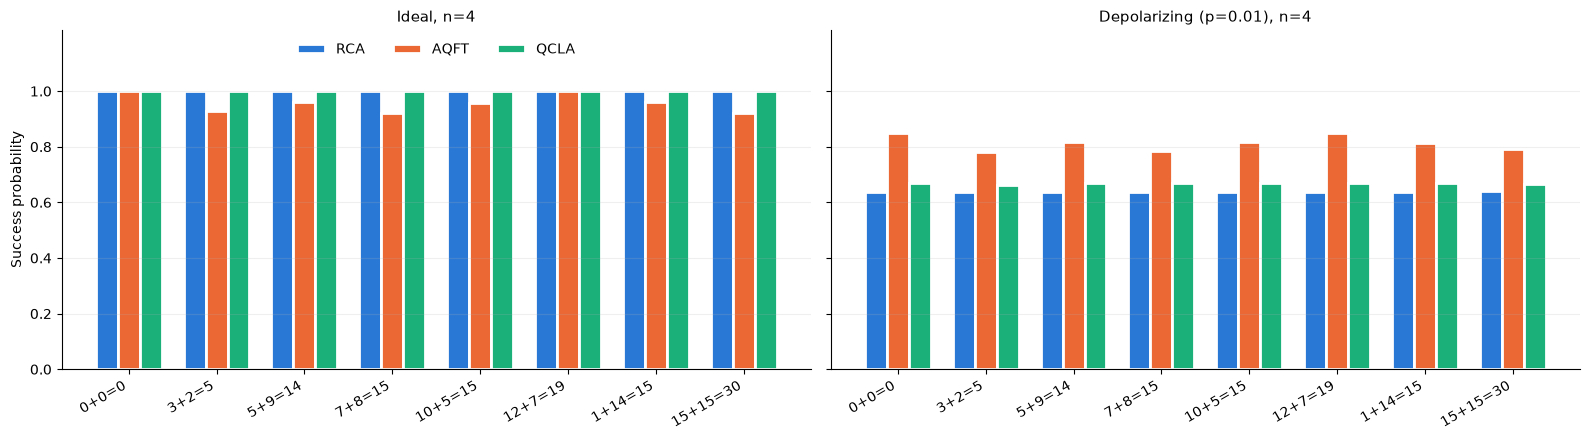

In [10]:
N_SUMS = 4
SUM_PAIRS = [(0, 0), (3, 2), (5, 9), (7, 8), (10, 5), (12, 7), (1, 14), (15, 15)]
sum_env = {"Ideal": None, "Depolarizing (p=0.01)": custom_noise_model_1}

sum_rows = []
for a, b in SUM_PAIRS:
    for r in run_experiment(N_SUMS, a, b, shots=2048, environments=sum_env, verbose=False):
        r["sum"] = f"{a}+{b}={a + b}"
        sum_rows.append(r)
sums = pd.DataFrame(sum_rows)
display((sums.pivot_table(index="sum", columns=["environment", "adder"], values="success_rate", sort=False) * 100)
        .round(1))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
xi = np.arange(len(SUM_PAIRS)); width = 0.25
for ax, env in zip(axes, sum_env):
    d = sums[sums.environment == env]
    for i, adder in enumerate(ADDER_COLORS):
        rates = [d[(d["sum"] == lab) & (d.adder == adder)].success_rate.iloc[0]
                 for lab in d["sum"].unique()]
        ax.bar(xi + (i - 1) * width, rates, width, label=adder, color=ADDER_COLORS[adder],
               edgecolor="white", linewidth=2)
    ax.set_xticks(xi); ax.set_xticklabels(d["sum"].unique(), rotation=30, ha="right")
    ax.set_title(f"{env}, n={N_SUMS}", fontsize=11)
    ax.grid(axis="y", alpha=0.2); ax.spines[["top", "right"]].set_visible(False)
    ax.set_ylim(0, 1.22); ax.set_yticks(np.arange(0, 1.01, 0.2))
axes[0].set_ylabel("Success probability")
axes[0].legend(frameon=False, ncol=3, loc="upper center")
plt.tight_layout(); plt.show()

## Experiment 1: success rate for n = 3 … 8

Each n prints its results and draws the same bar chart as the original notebook. Measured runtime for the whole loop: about 21 minutes on a 2-core, 8 GB machine (more cores help, since Aer parallelizes shots). Almost all of it is the two hardware noise models; ideal and depolarizing runs take about a minute together. Lower `SHOTS` for a quick pass.

Note: AQFT at n = 3 (ideal) now gives about 72% instead of 85.5%. The carry is the AQFT adder's least accurate bit (see the verification section above), and the old measurement never read it.


n=3 | Ideal
  RCA    10 qubits  statevector           100.0% success  (0.0 s)
  AQFT    7 qubits  statevector            72.1% success  (0.0 s)
  QCLA   13 qubits  statevector           100.0% success  (0.0 s)

n=3 | Depolarizing (p=0.01)
  RCA    10 qubits  matrix_product_state   71.8% success  (1.9 s)
  AQFT    7 qubits  matrix_product_state   68.6% success  (0.8 s)
  QCLA   13 qubits  matrix_product_state   81.3% success  (1.3 s)

n=3 | Hardware (FakeKyiv)
  RCA    10 qubits  matrix_product_state   59.5% success  (11.1 s)
  AQFT    7 qubits  matrix_product_state   64.6% success  (3.3 s)
  QCLA   13 qubits  matrix_product_state   78.8% success  (4.5 s)

n=3 | Hardware (FakeAachen)
  RCA    10 qubits  matrix_product_state   78.2% success  (11.5 s)
  AQFT    7 qubits  matrix_product_state   68.2% success  (4.8 s)
  QCLA   13 qubits  matrix_product_state   95.9% success  (6.0 s)


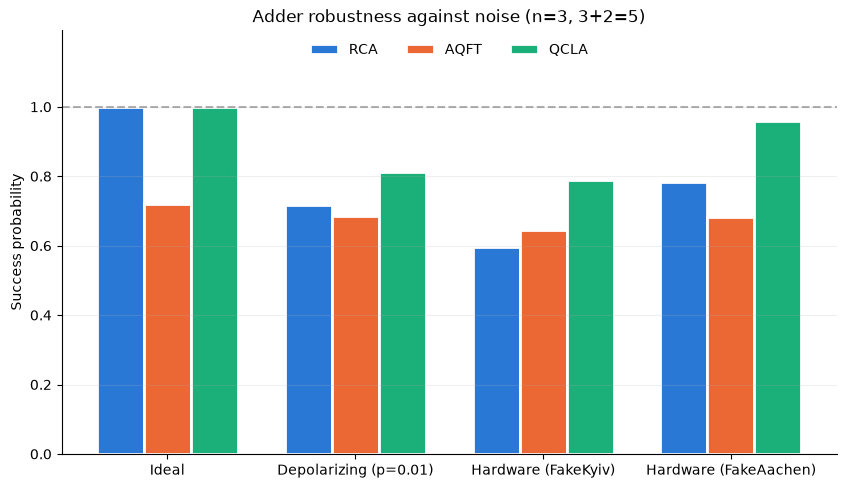


n=4 | Ideal
  RCA    13 qubits  statevector           100.0% success  (0.0 s)
  AQFT    9 qubits  statevector            92.4% success  (0.0 s)
  QCLA   18 qubits  statevector           100.0% success  (0.0 s)

n=4 | Depolarizing (p=0.01)
  RCA    13 qubits  matrix_product_state   62.7% success  (3.0 s)
  AQFT    9 qubits  matrix_product_state   77.9% success  (1.4 s)
  QCLA   18 qubits  matrix_product_state   66.7% success  (3.0 s)

n=4 | Hardware (FakeKyiv)
  RCA    13 qubits  matrix_product_state   52.0% success  (17.6 s)
  AQFT    9 qubits  matrix_product_state   66.6% success  (5.9 s)
  QCLA   18 qubits  matrix_product_state   78.8% success  (11.6 s)

n=4 | Hardware (FakeAachen)
  RCA    13 qubits  matrix_product_state   76.0% success  (20.1 s)
  AQFT    9 qubits  matrix_product_state   82.1% success  (6.3 s)
  QCLA   18 qubits  matrix_product_state   91.0% success  (11.9 s)


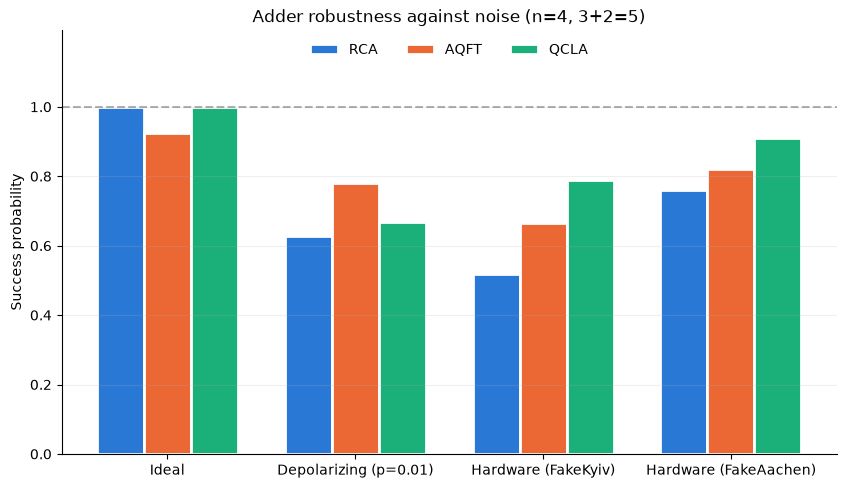


n=5 | Ideal
  RCA    16 qubits  statevector           100.0% success  (0.0 s)
  AQFT   11 qubits  statevector            92.4% success  (0.0 s)
  QCLA   22 qubits  statevector           100.0% success  (0.2 s)

n=5 | Depolarizing (p=0.01)
  RCA    16 qubits  matrix_product_state   55.2% success  (3.4 s)
  AQFT   11 qubits  matrix_product_state   74.2% success  (1.9 s)
  QCLA   22 qubits  matrix_product_state   61.7% success  (4.2 s)

n=5 | Hardware (FakeKyiv)
  RCA    16 qubits  matrix_product_state   50.4% success  (29.9 s)
  AQFT   11 qubits  matrix_product_state   61.5% success  (7.0 s)
  QCLA   22 qubits  matrix_product_state   84.6% success  (18.0 s)

n=5 | Hardware (FakeAachen)
  RCA    16 qubits  matrix_product_state   73.9% success  (29.4 s)
  AQFT   11 qubits  matrix_product_state   77.5% success  (8.9 s)
  QCLA   22 qubits  matrix_product_state   47.7% success  (10.9 s)


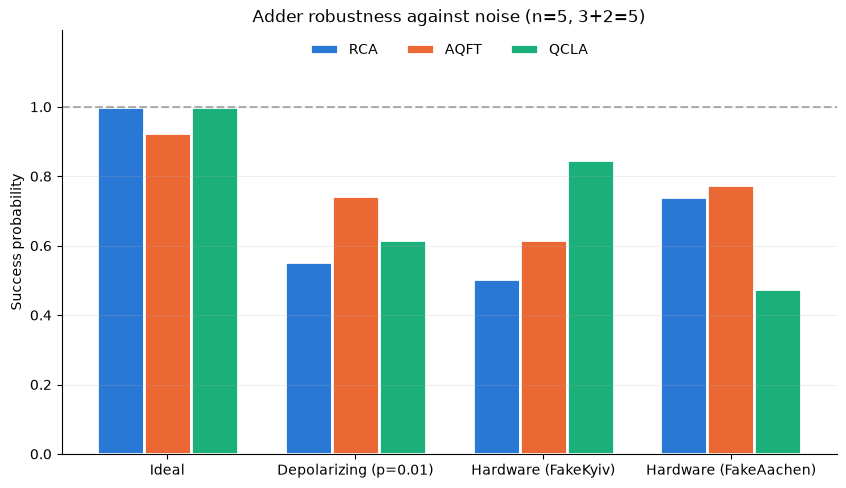


n=6 | Ideal
  RCA    19 qubits  statevector           100.0% success  (0.0 s)
  AQFT   13 qubits  statevector            92.4% success  (0.0 s)
  QCLA   27 qubits  matrix_product_state  100.0% success  (0.0 s)

n=6 | Depolarizing (p=0.01)
  RCA    19 qubits  matrix_product_state   47.4% success  (4.4 s)
  AQFT   13 qubits  matrix_product_state   70.0% success  (2.7 s)
  QCLA   27 qubits  matrix_product_state   50.7% success  (5.9 s)

n=6 | Hardware (FakeKyiv)
  RCA    19 qubits  matrix_product_state   45.5% success  (45.9 s)
  AQFT   13 qubits  matrix_product_state   56.4% success  (9.7 s)
  QCLA   27 qubits  matrix_product_state   60.3% success  (28.1 s)

n=6 | Hardware (FakeAachen)
  RCA    19 qubits  matrix_product_state   72.9% success  (38.4 s)
  AQFT   13 qubits  matrix_product_state   78.8% success  (9.9 s)
  QCLA   27 qubits  matrix_product_state   43.5% success  (24.3 s)


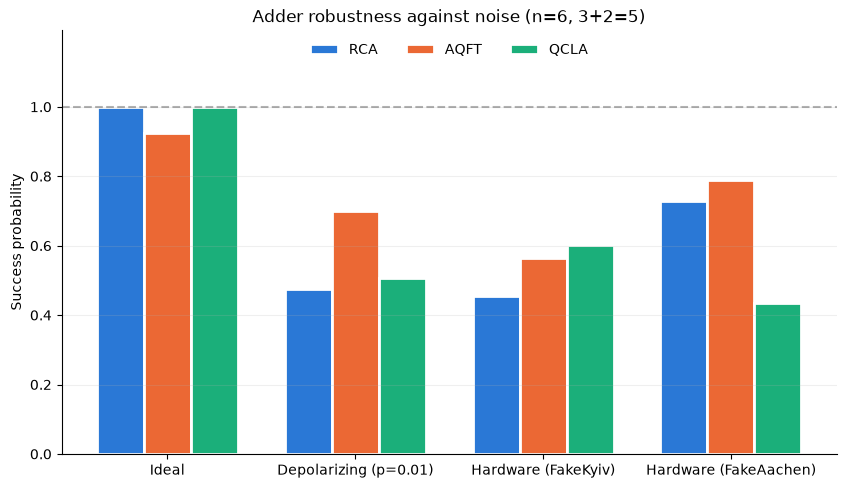


n=7 | Ideal
  RCA    22 qubits  statevector           100.0% success  (0.2 s)
  AQFT   15 qubits  statevector            92.4% success  (0.0 s)
  QCLA   31 qubits  matrix_product_state  100.0% success  (0.0 s)

n=7 | Depolarizing (p=0.01)
  RCA    22 qubits  matrix_product_state   41.8% success  (5.7 s)
  AQFT   15 qubits  matrix_product_state   67.0% success  (3.7 s)
  QCLA   31 qubits  matrix_product_state   47.1% success  (8.6 s)

n=7 | Hardware (FakeKyiv)
  RCA    22 qubits  matrix_product_state   43.6% success  (51.3 s)
  AQFT   15 qubits  matrix_product_state   56.4% success  (10.0 s)
  QCLA   31 qubits  matrix_product_state   61.6% success  (34.3 s)

n=7 | Hardware (FakeAachen)
  RCA    22 qubits  matrix_product_state   72.6% success  (41.6 s)
  AQFT   15 qubits  matrix_product_state   79.7% success  (10.6 s)
  QCLA   31 qubits  matrix_product_state   48.2% success  (20.9 s)


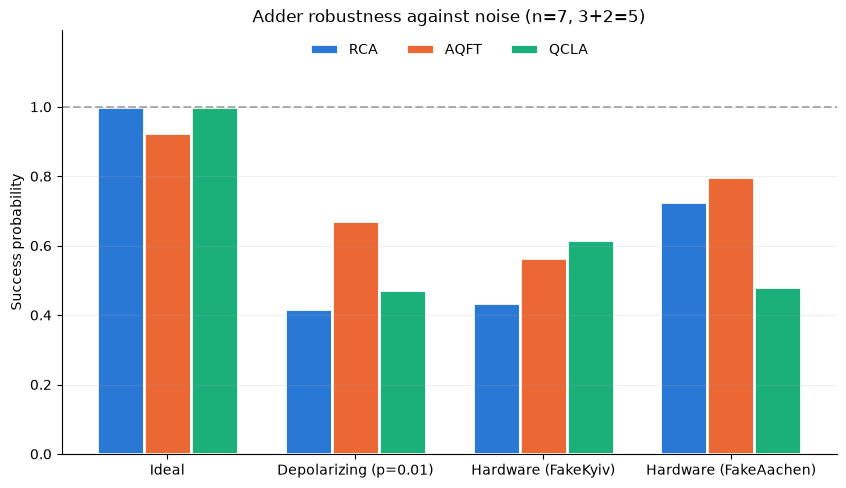


n=8 | Ideal
  RCA    25 qubits  matrix_product_state  100.0% success  (0.0 s)
  AQFT   17 qubits  statevector            98.2% success  (0.0 s)
  QCLA   37 qubits  matrix_product_state  100.0% success  (0.0 s)

n=8 | Depolarizing (p=0.01)
  RCA    25 qubits  matrix_product_state   36.6% success  (5.4 s)
  AQFT   17 qubits  matrix_product_state   60.2% success  (4.5 s)
  QCLA   37 qubits  matrix_product_state   38.2% success  (8.7 s)

n=8 | Hardware (FakeKyiv)
  RCA    25 qubits  matrix_product_state   34.8% success  (57.4 s)
  AQFT   17 qubits  matrix_product_state   57.8% success  (16.7 s)
  QCLA   37 qubits  matrix_product_state   62.2% success  (59.8 s)

n=8 | Hardware (FakeAachen)
  RCA    25 qubits  matrix_product_state   70.2% success  (51.3 s)
  AQFT   17 qubits  matrix_product_state   83.3% success  (17.8 s)
  QCLA   37 qubits  matrix_product_state   31.8% success  (48.2 s)


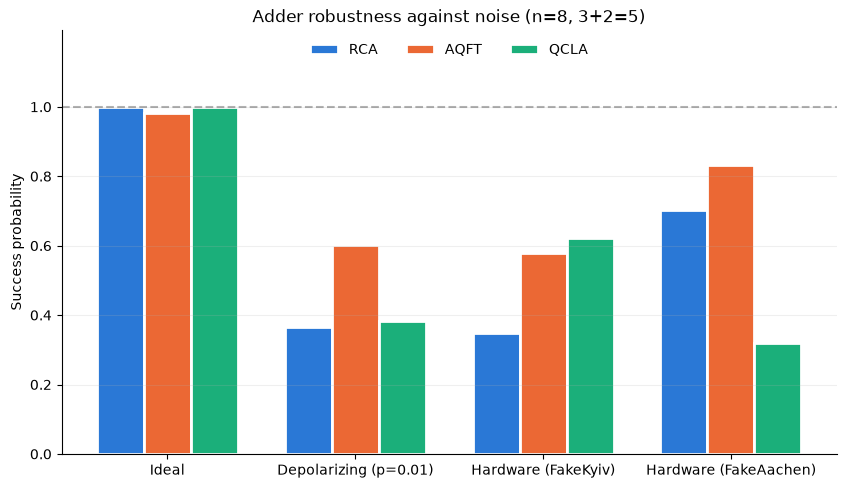

In [11]:
N_VALUES = [3, 4, 5, 6, 7, 8]
SHOTS = 4096
x, y = 3, 2   # target sum = 5

all_rows = []
for n in N_VALUES:
    rows = run_experiment(n, x, y, shots=SHOTS)
    all_rows.extend(rows)
    df_n = pd.DataFrame(rows)
    plot_success_bars(df_n, f"Adder robustness against noise (n={n}, {x}+{y}={x+y})")

results = pd.DataFrame(all_rows)
results.drop(columns=["sim_ops"]).to_csv("success_rates.csv", index=False)

### Summary table and success rate vs. n

n                                  3        4        5        6        7  \
environment           adder                                                
Ideal                 AQFT    72.1 %   92.4 %   92.4 %   92.4 %   92.4 %   
                      QCLA   100.0 %  100.0 %  100.0 %  100.0 %  100.0 %   
                      RCA    100.0 %  100.0 %  100.0 %  100.0 %  100.0 %   
Depolarizing (p=0.01) AQFT    68.6 %   77.9 %   74.2 %   70.0 %   67.0 %   
                      QCLA    81.3 %   66.7 %   61.7 %   50.7 %   47.1 %   
                      RCA     71.8 %   62.7 %   55.2 %   47.4 %   41.8 %   
Hardware (FakeKyiv)   AQFT    64.6 %   66.6 %   61.5 %   56.4 %   56.4 %   
                      QCLA    78.8 %   78.8 %   84.6 %   60.3 %   61.6 %   
                      RCA     59.5 %   52.0 %   50.4 %   45.5 %   43.6 %   
Hardware (FakeAachen) AQFT    68.2 %   82.1 %   77.5 %   78.8 %   79.7 %   
                      QCLA    95.9 %   91.0 %   47.7 %   43.5 %   48.2 %   
                      RCA     78.2 %   76.0 %   73.9 %   72.9 %   72.6 %   

n                                  8  
environment           adder           
Ideal                 AQFT    98.2 %  
                      QCLA   100.0 %  
                      RCA    100.0 %  
Depolarizing (p=0.01) AQFT    60.2 %  
                      QCLA    38.2 %  
                      RCA     36.6 %  
Hardware (FakeKyiv)   AQFT    57.8 %  
                      QCLA    62.2 %  
                      RCA     34.8 %  
Hardware (FakeAachen) AQFT    83.3 %  
                      QCLA    31.8 %  
                      RCA     70.2 %

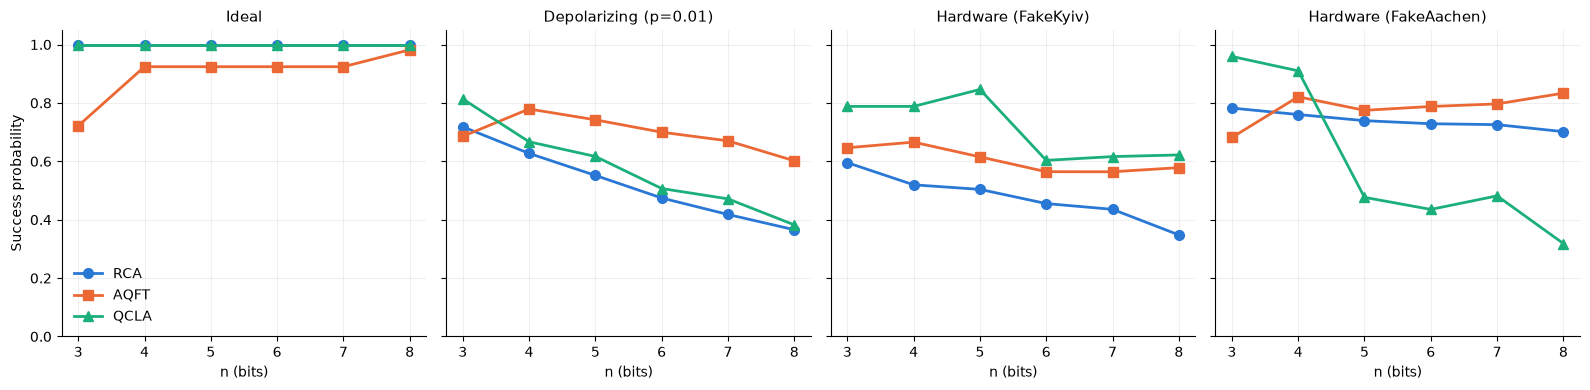

n,3,4,5,6,7,8
Total simulation time (s) per adder,,,,,,
AQFT,8.89,13.63,17.93,22.27,24.28,39.11
QCLA,11.91,26.56,33.39,58.36,63.83,116.68
RCA,24.58,40.79,62.79,88.70,98.85,114.13


In [12]:
summary = results.pivot_table(index=["environment", "adder"], columns="n", values="success_rate")
summary = summary.reindex(env_names, level=0)
display((summary * 100).round(1).astype(str) + " %")

fig, axes = plt.subplots(1, len(env_names), figsize=(16, 4), sharey=True)
for ax, env in zip(axes, env_names):
    d = results[results.environment == env]
    for adder, color in ADDER_COLORS.items():
        s = d[d.adder == adder].sort_values("n")
        ax.plot(s.n, s.success_rate, color=color, marker=ADDER_MARKERS[adder], linewidth=2,
                markersize=7, label=adder)
    ax.set_title(env, fontsize=11)
    ax.set_xlabel("n (bits)")
    ax.set_xticks(N_VALUES)
    ax.grid(alpha=0.2); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Success probability")
axes[0].set_ylim(0, 1.05)
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

display(results.pivot_table(index="adder", columns="n", values="runtime_s", aggfunc="sum")
        .rename_axis("Total simulation time (s) per adder"))

## Experiment 2: native `ccx` gates (`basis_gates = ['u3', 'cx', 'cp', 'ccx']`)

**Why this cell changed.** The original version transpiled to this basis and then ran the four usual noise environments. None of those models put an error on the gates that remained:

* `custom_noise_model_1` only has errors on `cx` and `cp`, so every `ccx` was perfect.
* FakeKyiv only defines gate errors on `ecr`, `sx`, `x`, `id`, and FakeAachen on `cz`, `sx`, `x`, `id`. Native `u3`, `cx`, `cp` and `ccx` were all noiseless, leaving only readout error.

That made RCA and QCLA (all Toffolis) look far better than they are. This version compares only the environments where the result means something: ideal, and depolarizing noise that includes a 1% error on each native `ccx`. In Experiment 1 the same Toffoli is decomposed into 6 `cx` gates, each with a 1% error; the difference between the two experiments shows how much the gate-set assumption matters.


n=5 | Ideal
  RCA    16 qubits  statevector           100.0% success  (0.0 s)
  AQFT   11 qubits  statevector            92.4% success  (0.0 s)
  QCLA   22 qubits  statevector           100.0% success  (0.2 s)

n=5 | Depolarizing, native ccx (p=0.01)
  RCA    16 qubits  matrix_product_state   81.7% success  (1.0 s)
  AQFT   11 qubits  matrix_product_state   74.2% success  (1.5 s)
  QCLA   22 qubits  matrix_product_state   85.2% success  (1.8 s)


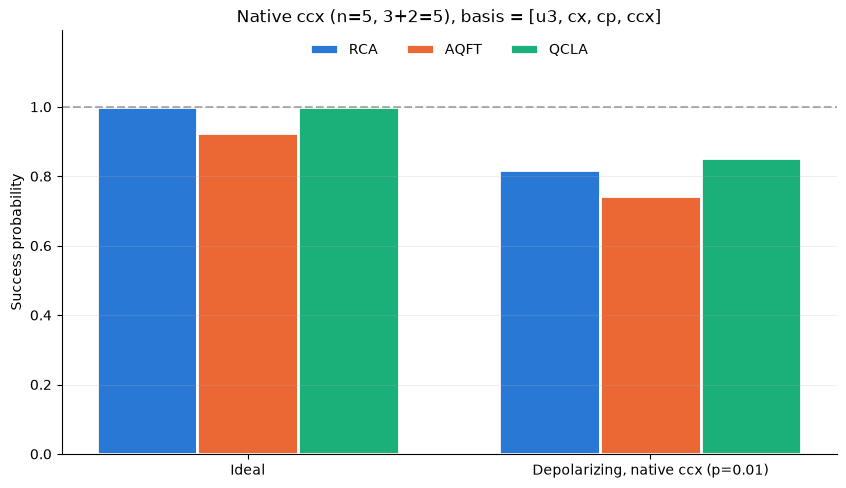

In [13]:
basis_env = {
    "Ideal": None,
    "Depolarizing, native ccx (p=0.01)": gate_level_noise_model,
}
n_basis = 5
basis_rows = run_experiment(n_basis, x, y, shots=SHOTS, environments=basis_env,
                            basis_gates=['u3', 'cx', 'cp', 'ccx'])
df_basis = pd.DataFrame(basis_rows)
plot_success_bars(df_basis, f"Native ccx (n={n_basis}, {x}+{y}={x+y}), basis = [u3, cx, cp, ccx]")

## Circuit metrics

Computed on the adder alone (no input encoding, no measurement), at three levels:

| Level | What it is | Columns |
|---|---|---|
| **Logical** | Flattened into `x, h, cx, cp, ccx, swap, p` | `gate_count`, `depth`, `two_qubit_gates` (cx, cp, swap), `ccx`, `count_ops` |
| **Clifford+T** | Every gate rewritten into `h, s, sdg, z, t, tdg, cx` | `ct_gate_count`, `ct_depth`, `ct_cx`, `t_count`, `t_depth` |
| **Device** | Transpiled to FakeKyiv / FakeAachen with routing (`optimization_level=1`) | `kyiv_depth`, `kyiv_2q`, `aachen_depth`, `aachen_2q` |

How the T metrics are computed:

* Each Toffoli uses Qiskit's textbook decomposition (7 T gates, 6 CNOTs). No T-gate cancellation between neighbouring Toffolis is attempted, so `t_count` is an upper bound. Optimized Toffoli constructions (for example a relative-phase Toffoli for the uncompute half, or temporary logical-AND) reach roughly 4 T per Toffoli.
* `t_depth` is the number of layers that contain a T or T† gate (`QuantumCircuit.depth` with a filter).
* `cp(λ)` becomes `p(λ/2)` on each qubit plus two CNOTs. Phases that are multiples of π/4 map exactly to Clifford+T. The AQFT adder also uses `cp(π/4)`, `cp(π/8)`, …, whose half-angles (π/8, π/16, …) are **not** exactly Clifford+T. They are counted in `arbitrary_rotations` and are **not** in `t_count` or `t_depth`.
* `t_count_with_synthesis` adds an estimate for those rotations: each needs about 3·log₂(1/ε) T gates with Ross-Selinger gridsynth (30 T at ε = 10⁻³). That makes the AQFT T-count comparable to RCA and QCLA. For RCA and QCLA the two columns are equal.

The Clifford+T rewrite was checked to be exactly equivalent (same unitary) to the original circuit for all three adders at n = 3.

Metrics don't need simulation, so they run fast even for large n.

In [14]:
class ArbitraryRotation(Gate):
    """Phase rotation that is not a multiple of pi/4 (not exactly Clifford+T)."""
    def __init__(self, theta):
        super().__init__('rz_arb', 1, [theta])

    def _define(self):
        qc = QuantumCircuit(1)
        qc.p(self.params[0], 0)
        self.definition = qc


LOGICAL_BASIS = ['x', 'h', 'cx', 'cp', 'ccx', 'swap', 'p']
CLIFFORD_T_BASIS = ['x', 'h', 'cx', 'p']   # p(theta) is classified afterwards
_PHASE_TO_GATES = {0: (), 1: (TGate(),), 2: (SGate(),), 3: (SGate(), TGate()), 4: (ZGate(),),
                   5: (ZGate(), TGate()), 6: (SdgGate(),), 7: (TdgGate(),)}


def bare_circuit(adder_gate):
    qc = QuantumCircuit(adder_gate.num_qubits)
    qc.append(adder_gate, range(adder_gate.num_qubits))
    return transpile(qc, basis_gates=LOGICAL_BASIS, optimization_level=0)


def to_clifford_t(qc, atol=1e-9):
    flat = transpile(qc, basis_gates=CLIFFORD_T_BASIS, optimization_level=0)
    out = QuantumCircuit(*flat.qregs, *flat.cregs)
    for inst in flat.data:
        op = inst.operation
        if op.name != 'p':
            out.append(op, inst.qubits, inst.clbits)
            continue
        k = float(op.params[0]) / (np.pi / 4)          # phase in units of pi/4
        if abs(k - round(k)) > atol:
            out.append(ArbitraryRotation(float(op.params[0])), inst.qubits)
        else:
            for g in _PHASE_TO_GATES[round(k) % 8]:
                out.append(g, inst.qubits)
    return out


def t_metrics(qc_ct, synthesis_eps=1e-3):
    ops = qc_ct.count_ops()
    t_count = ops.get('t', 0) + ops.get('tdg', 0)
    n_arb = ops.get('rz_arb', 0)
    t_per_rotation = int(np.ceil(3 * np.log2(1 / synthesis_eps)))   # Ross-Selinger estimate
    return dict(t_count=t_count,
                t_depth=qc_ct.depth(lambda i: i.operation.name in ('t', 'tdg')),
                arbitrary_rotations=n_arb,
                t_count_with_synthesis=t_count + n_arb * t_per_rotation)


def circuit_metrics(adder_gate, n, devices, seed=1234):
    logical = bare_circuit(adder_gate)
    ops = logical.count_ops()
    ct = to_clifford_t(logical)
    row = dict(n=n, adder=adder_gate.name, qubits=logical.num_qubits,
               gate_count=logical.size(), depth=logical.depth(),
               two_qubit_gates=logical.num_nonlocal_gates() - ops.get('ccx', 0),
               ccx=ops.get('ccx', 0),
               ct_gate_count=ct.size(), ct_depth=ct.depth(), ct_cx=ct.count_ops().get('cx', 0),
               **t_metrics(ct),
               count_ops=dict(ops), clifford_t_ops=dict(ct.count_ops()))
    for label, backend in devices.items():
        if logical.num_qubits > backend.num_qubits:
            continue
        dev = transpile(logical, backend=backend, optimization_level=1, seed_transpiler=seed)
        dops = dev.count_ops()
        row[f"{label}_depth"] = dev.depth()
        row[f"{label}_2q"] = sum(v for g, v in dops.items() if g in ('ecr', 'cz', 'cx'))
    return row

In [15]:
N_METRICS = list(range(3, 17))
devices = {"kyiv": fake_backend, "aachen": fake_backend2}

metric_rows = []
for n in N_METRICS:
    for adder_name, gate in make_adders(n).items():
        r = circuit_metrics(gate, n, devices)
        r["adder"] = adder_name
        metric_rows.append(r)
metrics = pd.DataFrame(metric_rows)

out = metrics.copy()
out["count_ops"] = out["count_ops"].apply(json.dumps)
out["clifford_t_ops"] = out["clifford_t_ops"].apply(json.dumps)
out.to_csv("circuit_metrics.csv", index=False)

cols = ["n", "adder", "qubits", "gate_count", "depth", "two_qubit_gates", "ccx",
        "t_count", "t_depth", "arbitrary_rotations", "t_count_with_synthesis",
        "kyiv_depth", "kyiv_2q", "aachen_depth", "aachen_2q"]
display(metrics[metrics.n.isin(N_VALUES)][cols].set_index(["n", "adder"]))

qubits  gate_count  depth  two_qubit_gates  ccx  t_count  t_depth  \
n adder                                                                      
3 RCA        10          22     18               12   10       70       30   
  AQFT        7          22     15               14    0       27       15   
  QCLA       13          22     10               12   10       70       24   
4 RCA        13          30     24               16   14       98       41   
  AQFT        9          37     19               27    0       36       25   
  QCLA       18          36     15               16   20      140       45   
5 RCA        16          38     30               20   18      126       52   
  AQFT       11          47     23               35    0       45       31   
  QCLA       22          44     15               20   24      168       45   
6 RCA        19          46     36               24   22      154       63   
  AQFT       13          57     27               43    0       54       37   
  QCLA       27          58     17               24   34      238       53   
7 RCA        22          54     42               28   26      182       74   
  AQFT       15          67     31               51    0       63       43   
  QCLA       31          66     17               28   38      266       53   
8 RCA        25          62     48               32   30      210       85   
  AQFT       17          94     35               76    0       72       49   
  QCLA       37          86     19               32   54      378       61   

         arbitrary_rotations  t_count_with_synthesis  kyiv_depth  kyiv_2q  \
n adder                                                                     
3 RCA                      0                      70         375      130   
  AQFT                     6                     207         155       58   
  QCLA                     0                      70         310      153   
4 RCA                      0                      98         505      185   
  AQFT                    33                    1026         276      120   
  QCLA                     0                     140         533      328   
5 RCA                      0                     126         665      237   
  AQFT                    45                    1395         320      154   
  QCLA                     0                     168         639      401   
6 RCA                      0                     154         769      292   
  AQFT                    57                    1764         392      206   
  QCLA                     0                     238         935      609   
7 RCA                      0                     182         888      365   
  AQFT                    69                    2133         499      246   
  QCLA                     0                     266         862      670   
8 RCA                      0                     210        1042      408   
  AQFT                   132                    4032         684      440   
  QCLA                     0                     378        1131     1040   

         aachen_depth  aachen_2q  
n adder                           
3 RCA             302        112  
  AQFT            133         55  
  QCLA            252        144  
4 RCA             413        169  
  AQFT            286        111  
  QCLA            542        332  
5 RCA             536        214  
  AQFT            364        163  
  QCLA            560        403  
6 RCA             696        277  
  AQFT            414        200  
  QCLA            753        639  
7 RCA             817        331  
  AQFT            500        261  
  QCLA            659        656  
8 RCA             940        382  
  AQFT            701        437  
  QCLA            924       1033

`count_ops` for each adder (logical level and after the Clifford+T rewrite), for the sizes simulated above:

In [16]:
for _, r in metrics[metrics.n.isin(N_VALUES)].iterrows():
    print(f"n={r.n:2d} {r.adder:5s} logical:     {r.count_ops}")
    print(f"           Clifford+T:  {r.clifford_t_ops}")

n= 3 RCA   logical:     {'cx': 12, 'ccx': 10}
           Clifford+T:  {'cx': 72, 't': 40, 'tdg': 30, 'h': 20}
n= 3 AQFT  logical:     {'cp': 14, 'h': 8}
           Clifford+T:  {'cx': 28, 't': 15, 'tdg': 12, 'h': 8, 's': 6, 'rz_arb': 6, 'sdg': 3}
n= 3 QCLA  logical:     {'cx': 12, 'ccx': 10}
           Clifford+T:  {'cx': 72, 't': 40, 'tdg': 30, 'h': 20}
n= 4 RCA   logical:     {'cx': 16, 'ccx': 14}
           Clifford+T:  {'cx': 100, 't': 56, 'tdg': 42, 'h': 28}
n= 4 AQFT  logical:     {'cp': 27, 'h': 10}
           Clifford+T:  {'cx': 54, 'rz_arb': 33, 't': 20, 'tdg': 16, 'h': 10, 's': 8, 'sdg': 4}
n= 4 QCLA  logical:     {'ccx': 20, 'cx': 16}
           Clifford+T:  {'cx': 136, 't': 80, 'tdg': 60, 'h': 40}
n= 5 RCA   logical:     {'cx': 20, 'ccx': 18}
           Clifford+T:  {'cx': 128, 't': 72, 'tdg': 54, 'h': 36}
n= 5 AQFT  logical:     {'cp': 35, 'h': 12}
           Clifford+T:  {'cx': 70, 'rz_arb': 45, 't': 25, 'tdg': 20, 'h': 12, 's': 10, 'sdg': 5}
n= 5 QCLA  logical:     {'ccx

### How the metrics scale with n

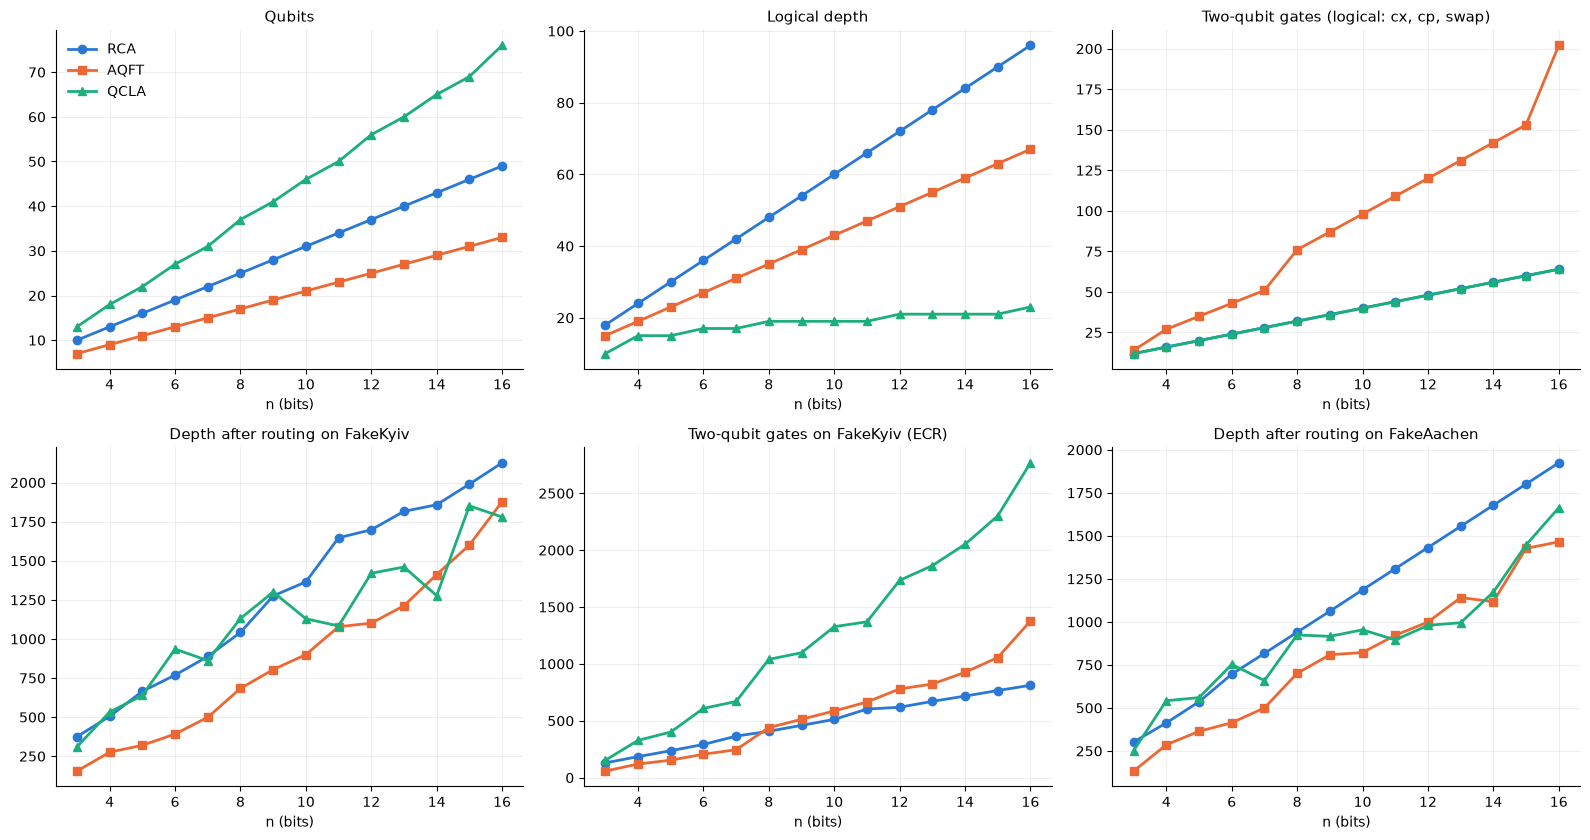

In [17]:
panels = [
    ("qubits", "Qubits"),
    ("depth", "Logical depth"),
    ("two_qubit_gates", "Two-qubit gates (logical: cx, cp, swap)"),
    ("kyiv_depth", "Depth after routing on FakeKyiv"),
    ("kyiv_2q", "Two-qubit gates on FakeKyiv (ECR)"),
    ("aachen_depth", "Depth after routing on FakeAachen"),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for ax, (col, title) in zip(axes.flat, panels):
    for adder, color in ADDER_COLORS.items():
        s = metrics[metrics.adder == adder].sort_values("n")
        ax.plot(s.n, s[col], color=color, marker=ADDER_MARKERS[adder], linewidth=2,
                markersize=6, label=adder)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("n (bits)")
    ax.grid(alpha=0.2); ax.spines[["top", "right"]].set_visible(False)
axes[0, 0].legend(frameon=False)
plt.tight_layout()
plt.savefig("circuit_metrics.png", dpi=150)
plt.show()

## Experiment 3: larger n with MPS

Proof that the MPS method reaches sizes far beyond what a statevector can hold. Depolarizing noise only, with fewer shots to keep the runtime short. QCLA at n = 12 has 56 qubits; its statevector would need 2^56 × 16 B ≈ 1 EiB.

In [18]:
RUN_LARGE = True
N_LARGE = [10, 12]
SHOTS_LARGE = 1024

if RUN_LARGE:
    large_env = {"Ideal": None, "Depolarizing (p=0.01)": custom_noise_model_1}
    large_rows = []
    for n in N_LARGE:
        large_rows += run_experiment(n, x, y, shots=SHOTS_LARGE, environments=large_env)
    large = pd.DataFrame(large_rows)
    display(large.pivot_table(index=["environment", "adder"], columns="n",
                              values=["qubits", "success_rate", "runtime_s"]))


n=10 | Ideal
  RCA    31 qubits  matrix_product_state  100.0% success  (0.0 s)
  AQFT   21 qubits  statevector            98.7% success  (0.2 s)
  QCLA   46 qubits  matrix_product_state  100.0% success  (0.0 s)

n=10 | Depolarizing (p=0.01)
  RCA    31 qubits  matrix_product_state   27.5% success  (1.9 s)
  AQFT   21 qubits  matrix_product_state   52.6% success  (1.4 s)
  QCLA   46 qubits  matrix_product_state   28.5% success  (3.2 s)

n=12 | Ideal
  RCA    37 qubits  matrix_product_state  100.0% success  (0.0 s)
  AQFT   25 qubits  matrix_product_state   98.0% success  (0.0 s)
  QCLA   56 qubits  matrix_product_state  100.0% success  (0.0 s)

n=12 | Depolarizing (p=0.01)
  RCA    37 qubits  matrix_product_state   21.6% success  (2.2 s)
  AQFT   25 qubits  matrix_product_state   44.6% success  (2.0 s)
  QCLA   56 qubits  matrix_product_state   22.2% success  (4.5 s)


qubits       runtime_s       success_rate  \
n                               10    12        10    12           10   
environment           adder                                             
Depolarizing (p=0.01) AQFT    21.0  25.0      1.40  2.02     0.526367   
                      QCLA    46.0  56.0      3.17  4.47     0.285156   
                      RCA     31.0  37.0      1.86  2.21     0.275391   
Ideal                 AQFT    21.0  25.0      0.16  0.04     0.987305   
                      QCLA    46.0  56.0      0.02  0.02     1.000000   
                      RCA     31.0  37.0      0.01  0.01     1.000000   

                                       
n                                  12  
environment           adder            
Depolarizing (p=0.01) AQFT   0.446289  
                      QCLA   0.221680  
                      RCA    0.215820  
Ideal                 AQFT   0.980469  
                      QCLA   1.000000  
                      RCA    1.000000

## Optional: run on real IBM hardware

This is the way past simulation limits. It uses `qiskit-ibm-runtime` for real (the rest of the notebook only borrows its fake backends) and needs a saved IBM Quantum account (`QiskitRuntimeService.save_account(...)`). It spends quantum time from your plan, so it is off by default.

In [19]:
RUN_ON_IBM = False

if RUN_ON_IBM:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
    from qiskit.transpiler import generate_preset_pass_manager

    service = QiskitRuntimeService()
    backend = service.least_busy(operational=True, simulator=False)
    print("Running on", backend.name)

    n_hw = 4
    pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
    circuits = {name: pm.run(setup_evaluation_circuit(g, n_hw, x, y))
                for name, g in make_adders(n_hw).items()}

    job = Sampler(mode=backend).run(list(circuits.values()), shots=4096)
    print("Job id:", job.job_id())
    target = bin(x + y)[2:].zfill(n_hw + 1)
    for name, pub_result in zip(circuits, job.result()):
        counts = pub_result.data.c.get_counts()
        print(f"{name}: {counts.get(target, 0) / 4096 * 100:.1f}% success")